# 02 · Manifold — principal-curve trajectory (whole malignant manifold)

Wang 2019's glioblastoma manifold is **non-branching**: the gastrulation /
somitogenesis / neural-crest developmental signatures form a single monotone gradient
(Gast & pSom weakly co-vary; Crest is the opposite, terminal end) rather than a hub
radiating to discrete subtypes. The correct topology is therefore a **principal curve**
(ElPiGraph, non-branching by construction) fit on the *joint* embedding — **not** a
re-embedding (re-embedding an anisotropic compartment fabricates folds; Kürten §4).

**Scope decision (derived, not inherited).** GBM resolves into transcriptional
compartments (Neftel meta-programs: Astrocyte-like, MES/Hypoxia, Oligo-progenitor/NPC).
We test whether the developmental axis is confined to one compartment (Kürten case,
scoping justified) or spans all of them (Bischoff/Sun case, whole manifold kept). Two
facts settle it here: (i) all compartments carry near-identical low cycling fractions,
so there is **no proliferation-confounded lobe to exclude**; (ii) the Crest terminus is
distributed across compartments. The proliferation split is **orthogonal** to the
developmental axis, so the whole manifold is the honest developmental object. The curve
is rooted at the gastrulation/somitogenesis-high tip and pseudotime flows to the
neural-crest terminus. Deliverable: `manifold.h5ad`, `manifold.pdf`.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold and score developmental modules
We keep all cells on their *original joint embedding coordinates* — no re-embedding.
The three embryonic signatures (Gastrulation / Somitogenesis / Neural-crest) are
scored against the shared **union** control pool and graph-smoothed to read geography
rather than 10x per-cell dropout.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']
from numpy.linalg import svd
c = xy - xy.mean(0); u,s,vt = svd(c, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}')

pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
# graph-smooth for geography
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
Smat = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): Smat = A @ Smat
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = Smat[:,j]

whole malignant manifold: 9634 cells on the joint embedding
UMAP aspect ratio (major/minor std): 1.56
Gast: 77/81 genes present
pSom: 92/98 genes present
Crest: 100/104 genes present


### Scope decision — whole manifold vs single compartment (data-driven)
Test whether the developmental axis is confined to one compartment or spans all. Two
facts settle it: (i) the smoothed developmental signatures behave as one axis (Gast/pSom
positively related, both opposite Crest); (ii) the compartments carry near-identical
developmental means and low cycling — no lobe is a proliferation confound — while the
Crest-high terminus is spread across compartments. Excluding any compartment would
truncate the very gradient under test, so the whole manifold is kept.

In [4]:
print('smoothed spatial correlations on the whole manifold:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
print('\nper-compartment smoothed developmental means + cycling:')
prof = adata.obs.groupby('compartment', observed=True)[['Gast_sm','pSom_sm','Crest_sm','cyc_score','cycling']].mean()
print(prof.round(4).to_string())
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
frac = adata.obs.loc[hi.values,'compartment'].value_counts(normalize=True).round(2).to_dict()
print('\nCrest-high decile distributed across compartments:', frac)
print('-> developmental axis is orthogonal to the compartment/proliferation split; keep whole manifold (no scoping).')
sub = adata   # whole manifold is the trajectory object

smoothed spatial correlations on the whole manifold:
  Gast_sm vs pSom_sm: r = +0.15
  Crest_sm vs Gast_sm: r = -0.48
  Crest_sm vs pSom_sm: r = -0.87

per-compartment smoothed developmental means + cycling:
             Gast_sm  pSom_sm  Crest_sm  cyc_score  cycling
compartment                                                
0.0          -0.0029  -0.0017    0.0016    -0.0261   0.1759
1.0          -0.0039   0.0049   -0.0043    -0.0229   0.2300
2.0          -0.0045   0.0150   -0.0115    -0.0159   0.1809

Crest-high decile distributed across compartments: {1.0: 0.53, 0.0: 0.45, 2.0: 0.02}
-> developmental axis is orthogonal to the compartment/proliferation split; keep whole manifold (no scoping).


### Fit the principal curve (ElPiGraph)
`Nodes/epg_lambda/epg_mu` give a **fold-free** monotone backbone: a node self-approach
ratio > 1 (minimum distance between graph-non-adjacent nodes, in units of median edge
length) certifies the curve does not fold back on itself. `epg_mu=100` is strong bending
regularisation, keeping the arc smooth rather than a sharp V. `Nodes=20` follows the
house 10x setting; the fold diagnostic below confirms the choice.

In [5]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3:
                dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks

with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

curve: 2 tips, 0 forks | fold self-approach ratio = 2.87 (>1 = fold-free)


### Derive the root (data-driven)
The root is the curve tip where Gast+pSom is highest and Crest lowest — the
developmental origin (neural crest is developmentally *late*; Kürten §3). Pseudotime
then flows to the neural-crest terminus. We also confirm pseudotime is **not** a
proliferation gradient by correlating it with the derived cycle score.

In [6]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm','cyc_score']:
    rho,p = spearmanr(t, sub.obs[s]); print(f'  {s}: rho={rho:+.3f} p={p:.1e}')
print('(cyc_score near-zero rho confirms pseudotime is developmental, not proliferation-driven)')

tip 0: Gast=-0.0048 pSom=-0.0029 Crest=+0.0032
tip 2: Gast=-0.0028 pSom=+0.0149 Crest=-0.0124
derived root = tip 2 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=+0.002 p=8.4e-01
  pSom_sm: rho=-0.638 p=0.0e+00
  Crest_sm: rho=+0.483 p=0.0e+00
  cyc_score: rho=+0.016 p=1.1e-01
(cyc_score near-zero rho confirms pseudotime is developmental, not proliferation-driven)


### Reorient to house style (pseudotime left → right)
Orient using only raw UMAP coordinates (discrete sign choice, no rotation — an SVD basis
can silently reflect an axis). This dataset's trajectory runs **horizontally** in the raw
embedding (corr(raw_x, pseudotime) ≈ −0.97), so the house transform flips x so low
pseudotime lands on the left; y is unchanged.

In [7]:
xy = sub.obsm['X_umap'].copy(); t = sub.obs['t'].values
xyr = np.column_stack([xy[:,0], xy[:,1]])
r = float(np.corrcoef(xyr[:,0], t)[0,1])
if r < 0:                                         # ensure low pt -> left
    xyr[:,0] = -xyr[:,0]; r = -r
assert r > 0, f'pseudotime not left->right (corr={r:+.2f})'
sub.obsm['X_umap_lin'] = xyr
print(f'orientation: x flipped to put low pseudotime left; corr(x_lin, pseudotime) = {r:+.2f}')

orientation: x flipped to put low pseudotime left; corr(x_lin, pseudotime) = +0.97


### Save manifold + trajectory figure (deliverable)

saved manifold.h5ad + manifold.pdf


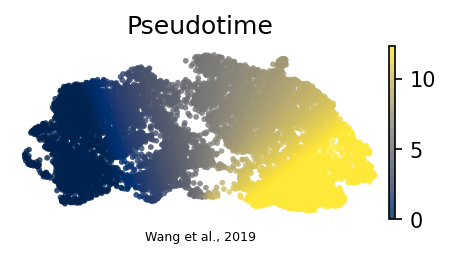

In [8]:
# sanitize non-serializable ElPiGraph uns entry (node positions kept; graph lives in uns['graph'])
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Wang et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')